# 49b. RG3 — 가스 RF + 주변 확장 운영 루프

49번에서 CN7은 '불량 발견 → 앞뒤 5샷 먼저 검사'로 5 → 8/15. RG3는 라벨 없는 점수로는 첫 불량을 못 찾아 효과 없음.
→ **검증된 RG3 가스 RF(8/17)를 기본 점수로 넣으면 주변 확장 이득이 RG3에서도 나오는지** 확인

| 기본 점수 | 내용 |
|---|---|
| gasrf_loro | Run 하나씩 빼고 학습 (43번과 같음). 다른 Run에 '나중 Run'도 포함 → 약간 유리 |
| **gasrf_forward** | **시간 순 학습**: 각 Run은 먼저 시작한 Run 라벨로만 학습 = 현장과 같은 조건 |
| combo | 49번 비교용 (라벨 없음) |

- 전략·예산은 49번과 같음 (100샷 묶음마다 10%), 시드 5개
- `gaps` 표: 같은 Run 안 불량 간격 → ±5샷 확장이 닿을 수 있는 비율 (확장 이득의 상한을 설명)
- 실행 시간: 수 분

In [1]:
import pandas as pd
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 300)
%load_ext autoreload
%autoreload 2
import rg3_active as RA, active_learning as AL
R = RA.run(seeds=(0, 1, 2, 3, 4), block=100)
print('시간 순 학습 정보'); display(R['D']['forward_info'])
print('대체(combo 순위)된 Run:', R['D']['fallback_runs'])

  [rg3] gasrf_loro 완료
  [rg3] gasrf_forward 완료
  [rg3] combo 완료
시간 순 학습 정보


,Run,학습에 쓴 이전 Run,이전 가스 수
0,rg3_R1,[],0
1,rg3_R2,[rg3_R1],0
2,rg3_R3,"[rg3_R1, rg3_R2]",4
3,rg3_R4,"[rg3_R1, rg3_R2, rg3_R3]",10
4,rg3_R5,"[rg3_R1, rg3_R2, rg3_R3, rg3_R4]",13
5,rg3_R6,"[rg3_R1, rg3_R2, rg3_R3, rg3_R4, rg3_R5]",17
6,rg3_R7,"[rg3_R1, rg3_R2, rg3_R3, rg3_R4, rg3_R5, rg3_R6]",17
7,rg3_R8,"[rg3_R1, rg3_R2, rg3_R3, rg3_R4, rg3_R5, rg3_R...",17


대체(combo 순위)된 Run: {'gasrf_loro': [], 'gasrf_forward': ['rg3_R1', 'rg3_R2']}


## 전략별 결과 (시드 평균, 전체 불량 25 = 가스 17 + 미성형 8)

In [2]:
display(R['summary'].round(3))

,기본 점수,전략,검사_샷,찾은_불량,범위,전체_불량,가스,가스_전체,미성형,미성형_전체,Precision,Recall,F1
0,gasrf_loro,S0 무작위,62,2.4,0~4,25,1.2,17,1.2,8,0.039,0.096,0.055
1,gasrf_loro,S1 고정 순위,62,8.0,8~8,25,7.0,17,1.0,8,0.129,0.320,0.184
2,gasrf_loro,S2 고정 + 주변 확장,62,7.0,7~7,25,5.0,17,2.0,8,0.113,0.280,0.161
3,gasrf_loro,S3 온라인 학습,62,5.0,4~6,25,3.8,17,1.2,8,0.081,0.200,0.115
4,gasrf_loro,S4 온라인 + 주변 확장,62,5.4,4~7,25,3.2,17,2.2,8,0.087,0.216,0.124
5,gasrf_forward,S0 무작위,62,2.4,0~4,25,1.2,17,1.2,8,0.039,0.096,0.055
6,gasrf_forward,S1 고정 순위,62,8.0,8~8,25,5.0,17,3.0,8,0.129,0.320,0.184
7,gasrf_forward,S2 고정 + 주변 확장,62,7.0,7~7,25,4.0,17,3.0,8,0.113,0.280,0.161
8,gasrf_forward,S3 온라인 학습,62,5.8,5~7,25,3.8,17,2.0,8,0.094,0.232,0.133
9,gasrf_forward,S4 온라인 + 주변 확장,62,6.0,4~7,25,3.6,17,2.4,8,0.097,0.240,0.138


## 이득 요약 — S2 − S1 > 0 이면 주변 확장이 RG3에서도 효과

In [3]:
display(RA.gain_table(R).round(2))

,기본 점수,S1 고정,S2 − S1 (주변 확장),S3 − S1 (온라인 학습),S4 − S1,무작위
0,gasrf_loro,8.0,-1.0,-3.0,-2.6,2.4
1,gasrf_forward,8.0,-1.0,-2.2,-2.0,2.4
2,combo,2.0,0.0,0.2,0.4,2.4


## 불량 간격 — RG3 불량이 얼마나 몰려 있나

In [4]:
display(R['gaps'].round(2))

,Run,불량 수,불량 seq,간격 중앙값,간격 ≤5 비율
0,rg3_R2,5,"28, 40, 45, 62, 82",14.5,0.25
1,rg3_R3,10,"7, 9, 12, 18, 30, 60, 62, 88, 132, 167",12.0,0.33
2,rg3_R4,4,"3, 23, 41, 65",20.0,0.00
3,rg3_R5,6,"33, 62, 69, 72, 146, 152",7.0,0.20


## 누적 발견 곡선

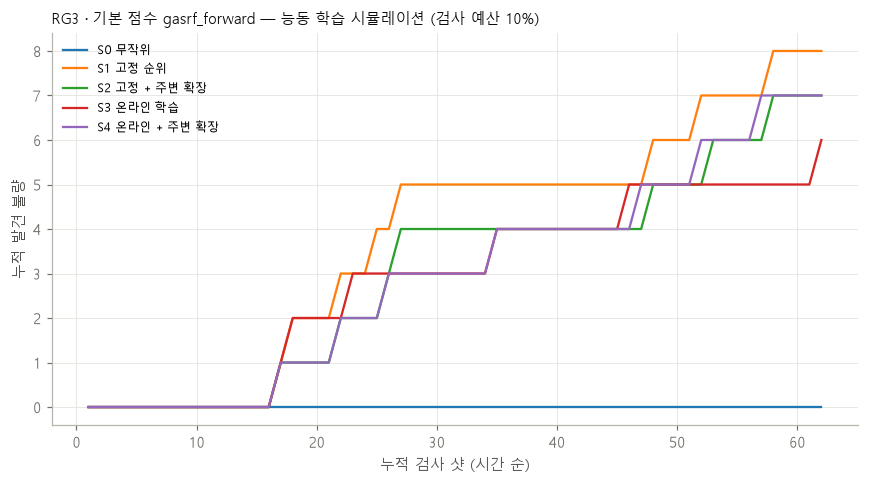

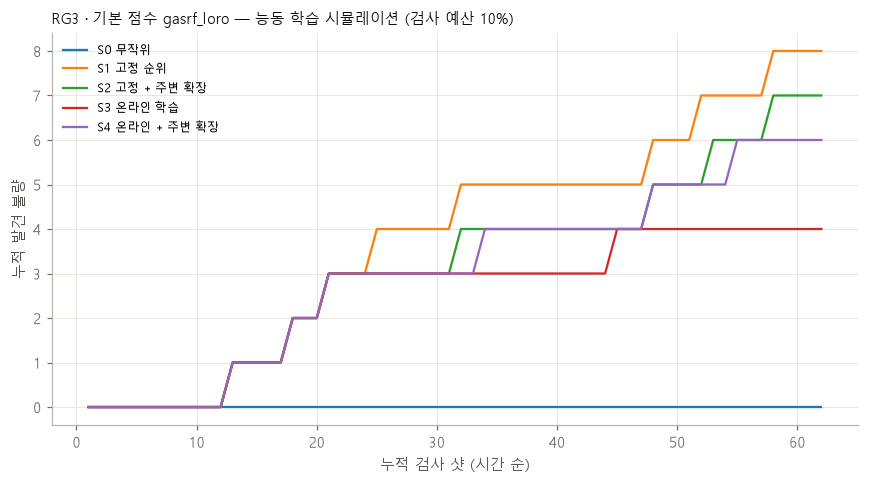

In [5]:
for b in ('gasrf_forward', 'gasrf_loro'):
    AL.plot_curves(R, 'rg3', b)

## Run별 — 첫 불량까지 검사 샷, 그 뒤 더 찾은 불량

In [6]:
E = R['episodes']
display(E.groupby(['기본 점수', '전략', 'Run'], sort=False)[['Run 불량', '첫 불량까지 검사 샷', '첫 발견 이후 찾은 불량']].mean().round(1))

Run 불량  첫 불량까지 검사 샷  첫 발견 이후 찾은 불량
기본 점수         전략             Run                                       
gasrf_loro    S0 무작위         rg3_R2     5.0          5.8            0.2
                             rg3_R3    10.0          5.7            0.0
                             rg3_R4     4.0          5.0            0.0
                             rg3_R5     6.0          7.0            0.0
              S1 고정 순위       rg3_R2     5.0          8.0            0.0
                             rg3_R3    10.0          2.0            3.0
                             rg3_R4     4.0          NaN            0.0
                             rg3_R5     6.0          4.0            2.0
              S2 고정 + 주변 확장  rg3_R2     5.0          8.0            0.0
                             rg3_R3    10.0          2.0            2.0
                             rg3_R4     4.0          NaN            0.0
                             rg3_R5     6.0          4.0            2.0
              S3 온라인 학습      rg3_R2     5.0          8.5            0.2
                             rg3_R3    10.0          2.8            1.8
                             rg3_R4     4.0          5.0            0.0
                             rg3_R5     6.0          1.5            0.2
              S4 온라인 + 주변 확장 rg3_R2     5.0          8.5            0.0
                             rg3_R3    10.0          2.4            1.6
                             rg3_R4     4.0          NaN            0.0
                             rg3_R5     6.0          3.8            1.0
gasrf_forward S0 무작위         rg3_R2     5.0          5.8            0.2
                             rg3_R3    10.0          5.7            0.0
                             rg3_R4     4.0          5.0            0.0
                             rg3_R5     6.0          7.0            0.0
              S1 고정 순위       rg3_R2     5.0          NaN            0.0
                             rg3_R3    10.0          1.0            4.0
                             rg3_R4     4.0          NaN            0.0
                             rg3_R5     6.0          4.0            2.0
              S2 고정 + 주변 확장  rg3_R2     5.0          NaN            0.0
                             rg3_R3    10.0          1.0            3.0
                             rg3_R4     4.0          NaN            0.0
                             rg3_R5     6.0          4.0            2.0
              S3 온라인 학습      rg3_R2     5.0          NaN            0.0
                             rg3_R3    10.0          1.2            3.2
                             rg3_R4     4.0          NaN            0.0
                             rg3_R5     6.0          4.6            0.6
              S4 온라인 + 주변 확장 rg3_R2     5.0          NaN            0.0
                             rg3_R3    10.0          1.2            2.8
                             rg3_R4     4.0          4.5            0.0
                             rg3_R5     6.0          6.0            0.8
combo         S0 무작위         rg3_R2     5.0          5.8            0.2
                             rg3_R3    10.0          5.7            0.0
                             rg3_R4     4.0          5.0            0.0
                             rg3_R5     6.0          7.0            0.0
              S1 고정 순위       rg3_R2     5.0          NaN            0.0
                             rg3_R3    10.0          NaN            0.0
                             rg3_R4     4.0          1.0            0.0
                             rg3_R5     6.0          5.0            0.0
              S2 고정 + 주변 확장  rg3_R2     5.0          NaN            0.0
                             rg3_R3    10.0          NaN            0.0
                             rg3_R4     4.0          1.0            0.0
                             rg3_R5     6.0          5.0            0.0
              S3 온라인 학습      rg3_R2     5.0          NaN            0.0
                             rg3_R3    10.0         18.0            0.0
     

## 확장 폭 민감도 (±3 / ±10샷)

In [7]:
for nb in (3, 10):
    Rn = RA.run(bases=('gasrf_forward',), seeds=(0, 1, 2), nbr=nb, verbose=False)
    print(f'===== ±{nb}샷'); display(RA.gain_table(Rn).round(2))

===== ±3샷


,기본 점수,S1 고정,S2 − S1 (주변 확장),S3 − S1 (온라인 학습),S4 − S1,무작위
0,gasrf_forward,8.0,-1.0,-2.0,-1.67,1.67


===== ±10샷


,기본 점수,S1 고정,S2 − S1 (주변 확장),S3 − S1 (온라인 학습),S4 − S1,무작위
0,gasrf_forward,8.0,-1.0,-2.0,-1.33,1.67


## 읽는 법
1. **gasrf_forward의 S1** = 현장 조건에서 가스 RF 단독 성능 (LORO보다 낮으면 '나중 Run 라벨' 덕을 봤던 것)
2. **S2 − S1**: RG3에서도 양수면 → '경보 → 검사 → 불량 확인 시 주변 확장'을 **두 제품 공통 운영 규칙**으로 제안 가능
3. 0이면 → `gaps`에서 RG3 불량 간격이 5샷보다 큰지 확인. 흩어져 있으면 확장이 닿지 않는 게 정상 → 'CN7처럼 몰려 나오는 불량에만 유효'로 범위를 한정
4. S3(온라인 학습)은 49번처럼 손해일 가능성 높음 → 보고서엔 '재학습보다 검사 순서 조정이 효과적'으로